<a href="https://colab.research.google.com/github/notiputipu/PCD_Assignment03/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Upload the input image
*files.upload()* opens Colab's file picker. The uploaded bytes are opened with Pillow and converted to RGB for displaying the original image. next(iter(uploaded)) selects the first uploaded file, select only one image for this experiment.

In [20]:
from google.colab import files
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt

# Upload one image
uploaded = files.upload()

# Open the uploaded image
image_name = next(iter(uploaded))
original_image = Image.open(io.BytesIO(uploaded[image_name])).convert("RGB")

Saving NonuniformIlluminationExample_01.png to NonuniformIlluminationExample_01 (2).png


# Display the original image


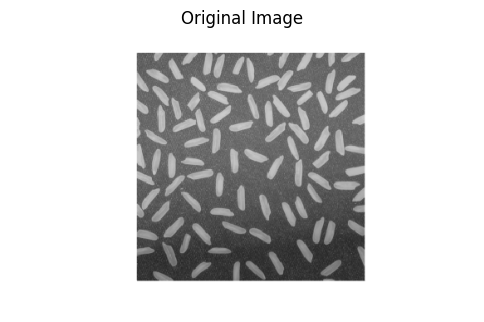

In [21]:
plt.figure(figsize=(6, 6))
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Convert greyscale and apply global thresholding

Grayscale conversion gives each pixel one intensity value from 0 to 255. A single threshold \(T\) is applied throughout the image:

B(r,c)=\begin{cases}1,&I(r,c)\geq T\\0,&I(r,c)<T\end{cases}

Here, \(I\) is the grayscale input and \(B\) is the binary output. A pixel equal to the threshold becomes foreground. The threshold is chosen manually; this code does not estimate an automatic or local threshold.

Keep the same threshold and input image when comparing morphological operations.

In [22]:
#global thresholding
def global_threshold(image, threshold):
    binary_image = []

    for row in image:
        binary_row = []

        for pixel in row:
            if pixel >= threshold:
                binary_row.append(1)
            else:
                binary_row.append(0)

        binary_image.append(binary_row)

    return binary_image

#convert to greyscale
grayscale = original_image.convert("L")
image = np.array(grayscale).tolist()

#apply one threshold to the entire image
threshold = 128
binary_image = global_threshold(image, threshold)

# Show the global thresholding result

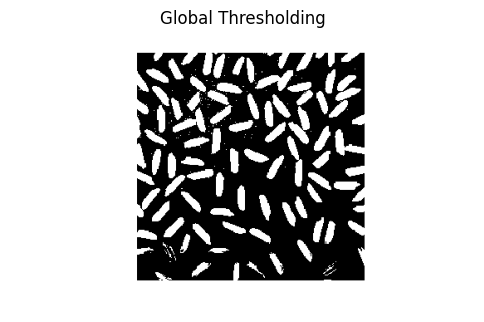

In [23]:
plt.figure(figsize=(6, 6))
plt.imshow(binary_image, cmap="gray")
plt.title("Global Thresholding")
plt.axis("off")
plt.show()

# Define the neighbour

The structuring element (SE) selects which nearby pixels take part in the operation. For a 3 × 3 mask, its centre is at index (1, 1).

row + se_row - centre_row and col + se_col - centre_col map each selected mask position to an image coordinate. A 1 in the mask selects a pixel; a 0 is a don't-care position. Coordinates outside the image contribute 0 (zero padding).

In [24]:
# collect the neighbours
def get_neighbours(image, row, col, se):
    height = len(image)
    width = len(image[0])

    centre_row = len(se) // 2
    centre_col = len(se[0]) // 2

    neighbours = []

    for se_row in range(len(se)):
        for se_col in range(len(se[0])):

            #ignoring zero in the elements
            if se[se_row][se_col] == 0:
                continue

            #map the position on the image
            neighbour_row = row + se_row - centre_row
            neighbour_col = col + se_col - centre_col

            #read the pixel if its inside the image
            if 0 <= neighbour_row < height and 0 <= neighbour_col < width:
                neighbours.append(image[neighbour_row][neighbour_col])
            else:
                neighbours.append(0)

    return neighbours

# Dilation

A pixel becomes white if any selected neighbour is white. This tends to expand foreground regions, shrink black gaps, and sometimes join nearby objects. int() converts Python's Boolean result into 1 or 0.

In [ ]:
# Dilation
def dilate(binary_image, se):
    height = len(binary_image)
    width = len(binary_image[0])

    output = [[0] * width for _ in range(height)]

    for row in range(height):
        for col in range(width):
            neighbours = get_neighbours(binary_image, row, col, se)
            output[row][col] = int(any(neighbours))

    return output

# Erosion

A pixel remains white only if all selected neighbours are white. This tends to shrink foreground regions and remove thin features or small white objects. It can also enlarge black holes.

In [ ]:
# Erosion
def erode(binary_image, se):
    height = len(binary_image)
    width = len(binary_image[0])

    output = [[0] * width for _ in range(height)]

    for row in range(height):
        for col in range(width):
            neighbours = get_neighbours(binary_image, row, col, se)
            output[row][col] = int(all(neighbours))

    return output

# Opening and Closing

*   Opening: erosion followed by dilation with the same SE. It removes foreground features that cannot accommodate the SE, including some small white specks and narrow protrusions.
*   Closing: dilation followed by erosion with the same SE. It can fill small black holes or narrow gaps, but can also connect nearby foreground objects.



In [ ]:
# Opening: erosion, then dilation
def opening(binary_image, se):
    eroded_image = erode(binary_image, se)
    return dilate(eroded_image, se)

# Closing: dilation, then erosion
def closing(binary_image, se):
    dilated_image = dilate(binary_image, se)
    return erode(dilated_image, se)


# Set the shaped for SE and display the output

In this experiment, I use a cross shapped pattern for the SE. The cross selects five positions which is the centre, above, below, left, and right. The four corners are ignored. In contrast, a 3 × 3 square selects all nine positions.

The display uses vmin=0 and vmax=1 so black and white have the same meaning for every morphology result.

To compare SE shapes, replace the cross with a square of ones, rerun this cell, then rerun all four operation cells below. Keep the image and threshold unchanged.

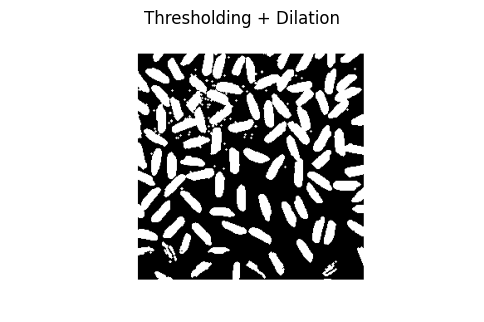

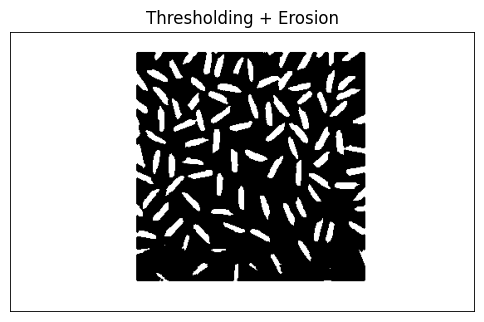

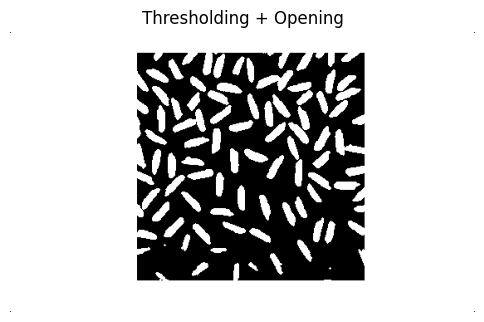

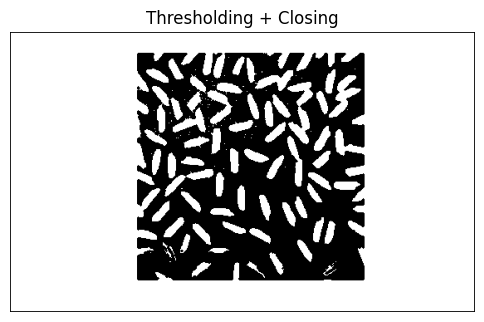

In [25]:
def show_result(result, title):
    plt.figure(figsize=(6, 6))
    plt.imshow(result, cmap="gray", vmin=0, vmax=1)
    plt.title(title)
    plt.axis("off")
    plt.show()

se = [
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
]

# Apply dilation and show its result
dilated_image = dilate(binary_image, se)
show_result(dilated_image, "Thresholding + Dilation")

# Apply erosion and show its result
eroded_image = erode(binary_image, se)
show_result(eroded_image, "Thresholding + Erosion")

# Apply opening and show its result
opened_image = opening(binary_image, se)
show_result(opened_image, "Thresholding + Opening")

# Apply closing and show its result
closed_image = closing(binary_image, se)
show_result(closed_image, "Thresholding + Closing")